# 30 — Seed-to-seed scatter and paired tests between architectures

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What it does.** Extension 2. Notebooks 06–07 compared architectures with one or two training seeds, so a difference of a few tenths could not be separated from the scatter caused by initialisation and data order. Here more seeds were trained with the same recipe (CNN with fresh injections: 5 seeds; hybrid convolution + attention: 3; patch Transformer: 3) and every seed is evaluated on the same test injections (notebooks 05–07) with thresholds from the validation noise. We report the mean ρ₅₀ over sine-Gaussian, pulse and chirp per seed, the mean and standard deviation across seeds, the gain of averaging the logits of the five CNNs, and **permutation and Welch tests** of the differences between architectures at the level of seeds (so that the training scatter, not only the test-set sampling, enters the uncertainty).

**What it does not do.** Three to five seeds give only a rough estimate of the scatter (the standard deviation of a handful of values has itself ±30–50 % uncertainty); the architectures are those of notebook 07, with its training budget (12 epochs for the attention models).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, pickle, itertools
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import seq_models as sm
import gwosc_tools as g
g.style()
CH, data, S1, DS = sm.load_data(); TEST = sm.make_test_sets(data, S1); SNRS = sm.SNRS; MORPHS = g.MORPHS
SEEDS = {"CNN (fresh)": ("cnn_fresh", [0, 1, 2, 3, 4]), "hybrid (fresh)": ("hyb_fresh", [0, 1, 2]), "Transformer (fresh)": ("tf16_fresh", [0, 1, 2])}
fn = os.path.join(g.CACHE, "stats30.pkl")
def logits(m, x): return m.predict(sm.clip(x)[..., None], verbose=0, batch_size=1024)[:, 0]
if os.path.exists(fn): LG = pickle.load(open(fn, "rb"))
else:
    LG = {}
    for lab, (name, seeds) in SEEDS.items():
        for s in seeds:
            m = sm.train_variant(name, None, None, seed=s, verbose=False)[0]; d = {"val": logits(m, DS["val"]["noise"])}
            for k, (x, c) in TEST.items(): d[k] = logits(m, x)
            LG[(lab, s)] = d; print(lab, s, flush=True)
    pickle.dump(LG, open(fn, "wb"))
print(len(LG), "evaluated networks")

CNN (fresh) 0


CNN (fresh) 1


CNN (fresh) 2


CNN (fresh) 3


CNN (fresh) 4


...

hybrid (fresh) 2


Transformer (fresh) 0


Transformer (fresh) 1


Transformer (fresh) 2


11 evaluated networks


In [2]:
def mean_rho50(d, far, bootstrap=False, B=100):
    r = [g.bootstrap_rho(d["val"], [d[(k, s)] for s in SNRS], SNRS, far, B=B if bootstrap else 1, seed=2) for k in MORPHS]
    p = np.mean([np.nan_to_num(x[0][0], nan=16) for x in r])
    return p if not bootstrap else (p, np.sqrt(sum(((g.ci(x[1][:, 0])[1] - g.ci(x[1][:, 0])[0]) / 2) ** 2 for x in r)) / 3)
rows = [dict(arch=lab, seed=s, FAP=far, rho50=mean_rho50(d, far)) for (lab, s), d in LG.items() for far in (1e-2, 1e-3)]
SD = pd.DataFrame(rows); T = SD.pivot_table(index=["arch", "seed"], columns="FAP", values="rho50"); print("mean rho50 over the three morphologies, per seed:"); display(T.round(2))
AG = SD.groupby(["arch", "FAP"]).rho50.agg(["mean", "std", "min", "max", "count"]).round(3); AG

mean rho50 over the three morphologies, per seed:


FAP                       0.001  0.010
arch                seed              
CNN (fresh)         0      5.66   4.57
                    1      5.64   4.63
                    2      5.72   4.56
                    3      5.66   3.72
                    4      5.70   4.08
Transformer (fresh) 0      7.25   6.29
                    1      7.51   6.24
                    2      7.64   6.33
hybrid (fresh)      0      6.14   5.36
                    1      6.27   5.30
                    2      6.46   5.40

mean    std    min    max  count
arch                FAP                                     
CNN (fresh)         0.001  5.674  0.034  5.637  5.720      5
                    0.010  4.314  0.397  3.724  4.630      5
Transformer (fresh) 0.001  7.467  0.199  7.248  7.638      3
                    0.010  6.290  0.046  6.242  6.334      3
hybrid (fresh)      0.001  6.290  0.160  6.138  6.456      3
                    0.010  5.353  0.051  5.300  5.402      3

In [3]:
# ensemble of the five CNNs (mean logit) and test-set bootstrap error of a single network, to compare with the seed scatter
ens = {"val": np.mean([LG[("CNN (fresh)", s)]["val"] for s in range(5)], 0)}
for k in TEST: ens[k] = np.mean([LG[("CNN (fresh)", s)][k] for s in range(5)], 0)
print("5-CNN ensemble: mean rho50 FAP 1e-2 = %.2f, 1e-3 = %.2f" % (mean_rho50(ens, 1e-2), mean_rho50(ens, 1e-3)))
b = mean_rho50(LG[("CNN (fresh)", 0)], 1e-2, True); print("single CNN seed 0: %.2f +- %.2f (test-set bootstrap) versus seed std %.2f" % (b[0], b[1], AG.loc[("CNN (fresh)", 1e-2), "std"]))

5-CNN ensemble: mean rho50 FAP 1e-2 = 3.79, 1e-3 = 5.32


single CNN seed 0: 4.57 +- 0.08 (test-set bootstrap) versus seed std 0.40


In [4]:
def perm_test(a, b, n=20000, rng=np.random.default_rng(0)):
    a, b = np.asarray(a), np.asarray(b); obs = a.mean() - b.mean(); pool = np.r_[a, b]; k = len(a)
    if len(set(itertools.chain(range(len(pool))))) and len(list(itertools.combinations(range(len(pool)), k))) <= 20000:
        diffs = [pool[list(c)].mean() - pool[[i for i in range(len(pool)) if i not in c]].mean() for c in itertools.combinations(range(len(pool)), k)]
    else:
        diffs = [(lambda p: p[:k].mean() - p[k:].mean())(rng.permutation(pool)) for _ in range(n)]
    return obs, float(np.mean(np.abs(diffs) >= abs(obs) - 1e-12))
rows = []
for far in (1e-2, 1e-3):
    for A, B_ in (("hybrid (fresh)", "CNN (fresh)"), ("Transformer (fresh)", "CNN (fresh)"), ("Transformer (fresh)", "hybrid (fresh)")):
        a = SD[(SD.arch == A) & (SD.FAP == far)].rho50.values; b = SD[(SD.arch == B_) & (SD.FAP == far)].rho50.values
        d, p = perm_test(a, b); t = stats.ttest_ind(a, b, equal_var=False)
        rows.append(dict(FAP=far, A=A, B=B_, diff=d, perm_p=p, welch_t=float(t.statistic), welch_p=float(t.pvalue), n=(len(a), len(b))))
PT = pd.DataFrame(rows); PT.round(4)

,FAP,A,B,diff,perm_p,welch_t,welch_p,n
0,0.010,hybrid (fresh),CNN (fresh),1.0391,0.0179,5.7789,0.0038,"(3, 5)"
1,0.010,Transformer (fresh),CNN (fresh),1.9761,0.0179,11.0174,0.0003,"(3, 5)"
2,0.010,Transformer (fresh),hybrid (fresh),0.9370,0.1000,23.4610,0.0000,"(3, 3)"
3,0.001,hybrid (fresh),CNN (fresh),0.6152,0.0179,6.5877,0.0194,"(3, 5)"
4,0.001,Transformer (fresh),CNN (fresh),1.7925,0.0179,15.4707,0.0036,"(3, 5)"
5,0.001,Transformer (fresh),hybrid (fresh),1.1772,0.1000,7.9945,0.0016,"(3, 3)"


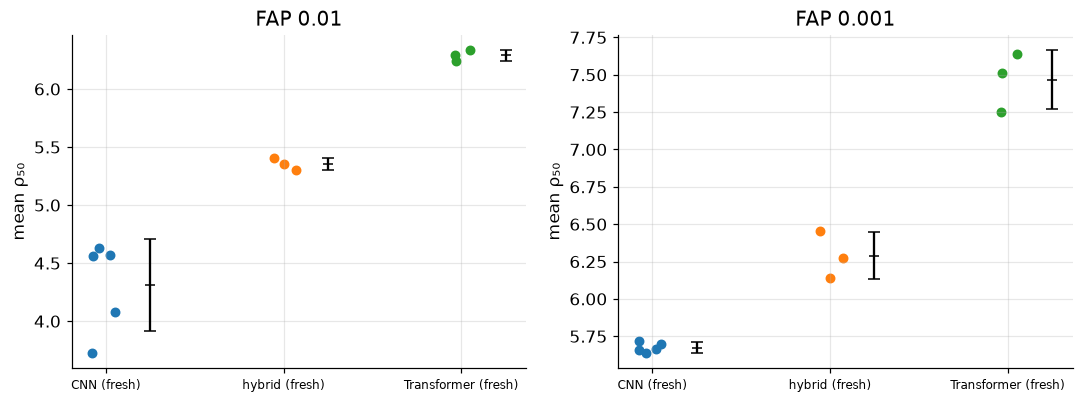

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), sharey=False)
for a, far in zip(ax, (1e-2, 1e-3)):
    for j, (lab, (name, seeds)) in enumerate(SEEDS.items()):
        v = SD[(SD.arch == lab) & (SD.FAP == far)].rho50.values; a.scatter(np.full(len(v), j) + np.random.default_rng(j).uniform(-.08, .08, len(v)), v, color=f"C{j}", s=30); a.errorbar(j + 0.25, v.mean(), v.std(ddof=1) if len(v) > 1 else 0, fmt="_", color="k", capsize=4)
    a.set_xticks(range(3)); a.set_xticklabels(SEEDS, fontsize=8); a.set_ylabel("mean ρ₅₀"); a.set_title(f"FAP {far:g}")
fig.tight_layout(); g.savefig(fig, "fig30_seed_scatter"); plt.show()
g.save_json(dict(per_seed=SD.to_dict("records"), summary=AG.reset_index().to_dict("records"), tests=PT.to_dict("records")), "30_summary.json")

## Output and next step

`results/30_summary.json`, `figures/fig30_seed_scatter`. Next: the coherent two-detector analysis and the Bayesian evidence extensions.